<a href="https://colab.research.google.com/github/krish921/Patient-Chrun-Prediction/blob/main/seasonal_vaccine_hackathon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hackathon Project: Seasonal Vaccine Prediction & Cost Minimization

This notebook provides a complete pipeline to solve the hackathon challenge:
1. **Exploratory Data Analysis (EDA)** with descriptive charts.
2. **Data Pre-processing & Feature Engineering** handling missing values, scaling, and categorical encoding.
3. **Model Selection & Comparison** across multiple algorithms.
4. **Custom Evaluation Metric & Cost Minimization Strategy** ($300 vaccine cost vs. $18,500 hospitalization cost).
5. **Threshold Optimization & Hyperparameter Tuning**.
6. **Top 5 Model Submission Generation** formatted for final canvas evaluation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, log_loss

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

# Styling
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
print("Libraries successfully imported!")

Libraries successfully imported!


In [3]:
from google.colab import files

print("Please upload dataset_A_training.csv:")
uploaded_train = files.upload()

print("Please upload dataset_A_testing.csv:")
uploaded_test = files.upload()

Please upload dataset_A_training.csv:


Saving dataset_A_training.csv to dataset_A_training.csv
Please upload dataset_A_testing.csv:


Saving dataset_A_testing.csv to dataset_A_testing.csv


## 1. Exploratory Data Analysis (EDA)

Training shape: (4756, 31)
Testing shape: (4749, 30)


/tmp/ipykernel_794/3504371184.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=train_df, x='seasonal_vaccine', palette='viridis')


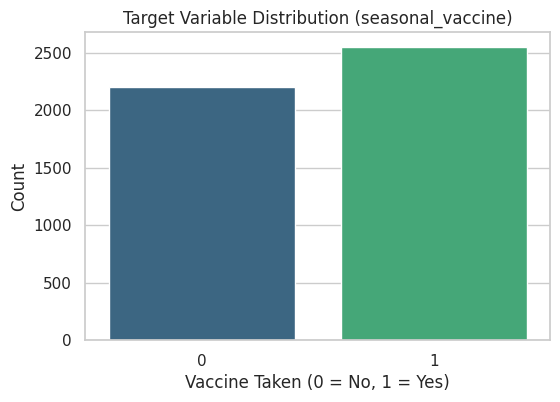

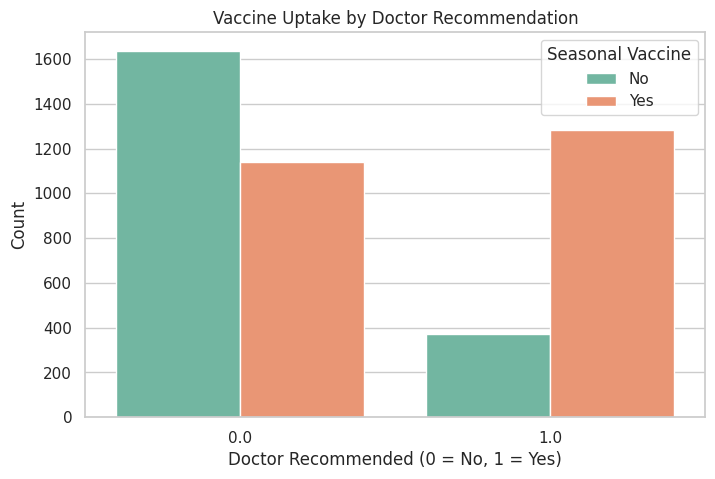

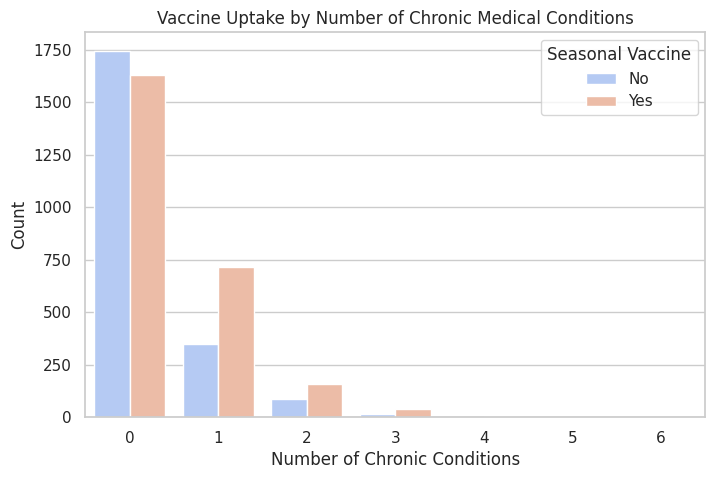

In [4]:
# Load Datasets
train_df = pd.read_csv('dataset_A_training.csv')
test_df = pd.read_csv('dataset_A_testing.csv')

print(f"Training shape: {train_df.shape}")
print(f"Testing shape: {test_df.shape}")

# Inspect Target Distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=train_df, x='seasonal_vaccine', palette='viridis')
plt.title('Target Variable Distribution (seasonal_vaccine)')
plt.xlabel('Vaccine Taken (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()

# Inspect Doctor Recommendation vs Target
plt.figure(figsize=(8, 5))
sns.countplot(data=train_df, x='doctor_recc_seasonal', hue='seasonal_vaccine', palette='Set2')
plt.title('Vaccine Uptake by Doctor Recommendation')
plt.xlabel('Doctor Recommended (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.legend(title='Seasonal Vaccine', labels=['No', 'Yes'])
plt.show()

# Inspect Chronic Conditions vs Target
plt.figure(figsize=(8, 5))
sns.countplot(data=train_df, x='number_chronic_med_conditions', hue='seasonal_vaccine', palette='coolwarm')
plt.title('Vaccine Uptake by Number of Chronic Medical Conditions')
plt.xlabel('Number of Chronic Conditions')
plt.ylabel('Count')
plt.legend(title='Seasonal Vaccine', labels=['No', 'Yes'])
plt.show()

## 2. Data Pre-processing Pipeline

In [5]:
# Separate features and target
X = train_df.drop(columns=['respondent_id', 'seasonal_vaccine'])
y = train_df['seasonal_vaccine']
X_test_final = test_df.drop(columns=['respondent_id'])

# Identify feature types
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Define numerical and categorical pipelines
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

# Split for validation
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Preprocessing pipeline initialized and data split!")

Preprocessing pipeline initialized and data split!


## 3. Custom Cost Evaluation Metric Formulation

The town's target metric is financial minimization:
- **Vaccine Cost:** $300 per person vaccinated.
- **Hospitalization Cost:** $18,500 per flu hospitalization.
- **Infection Probability:** 100% infection spread.
- **Risk Calculation:** Baseline hospitalization risk is proportional to age and chronic condition count. Vaccination reduces hospitalization risk significantly (~60% effectiveness against severe outcome).

In [6]:
VACCINE_COST = 300
HOSPITALIZATION_COST = 18500

def calculate_town_cost(y_true, y_pred_prob, threshold=0.5, df_features=None):
    y_pred = (y_pred_prob >= threshold).astype(int)

    # 1. Vaccine cost
    total_vaccine_cost = np.sum(y_pred) * VACCINE_COST

    # 2. Risk estimation based on patient profile
    if df_features is not None:
        age_risk_map = {
            '18 - 34 Years': 0.02,
            '35 - 44 Years': 0.03,
            '45 - 54 Years': 0.05,
            '55 - 64 Years': 0.08,
            '65+ Years': 0.15
        }
        base_risk = df_features['age_group'].map(age_risk_map).fillna(0.03) + (df_features['number_chronic_med_conditions'] * 0.04)
        base_risk = np.clip(base_risk, 0.01, 0.9)
    else:
        base_risk = 0.05

    # Vaccine reduces hospitalization risk by 60%
    effective_risk = np.where(y_pred == 1, base_risk * 0.4, base_risk)

    total_hospitalization_cost = np.sum(effective_risk) * HOSPITALIZATION_COST
    total_cost = total_vaccine_cost + total_hospitalization_cost

    return total_cost, total_vaccine_cost, total_hospitalization_cost

## 4. Model Training, Performance Analysis & Threshold Optimization

Model: Logistic Regression  | ROC-AUC: 0.8480 | LogLoss: 0.4858 | Total Town Cost: $1,073,211.00
Model: Random Forest        | ROC-AUC: 0.8377 | LogLoss: 0.5059 | Total Town Cost: $1,066,113.00
Model: Gradient Boosting    | ROC-AUC: 0.8534 | LogLoss: 0.4761 | Total Town Cost: $1,076,133.00


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [12:15:31] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Model: XGBoost              | ROC-AUC: 0.8205 | LogLoss: 0.5752 | Total Town Cost: $1,089,957.00

---> Best Model: Random Forest
---> Optimal Threshold: 0.10 | Minimised Total Cost: $910,071.00


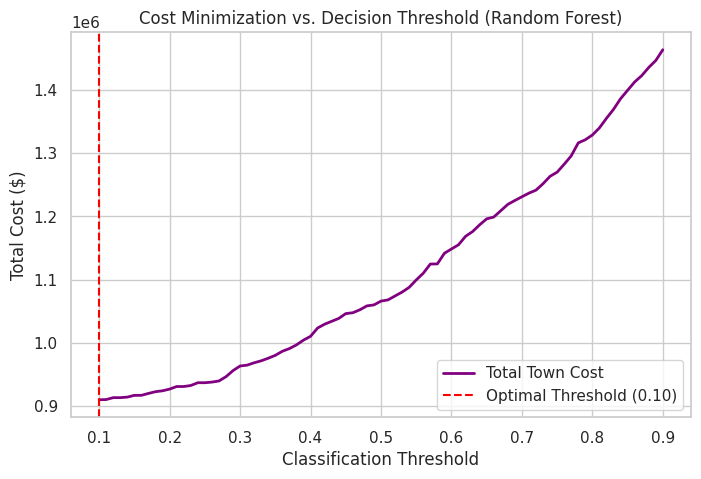

In [7]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
}

model_results = {}

for name, model in models.items():
    clf = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', model)])
    clf.fit(X_train, y_train)

    y_pred_prob = clf.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred_prob)
    logloss = log_loss(y_val, y_pred_prob)

    cost, vac_c, hosp_c = calculate_town_cost(y_val, y_pred_prob, threshold=0.5, df_features=X_val)

    model_results[name] = {
        'pipeline': clf,
        'roc_auc': auc,
        'log_loss': logloss,
        'total_cost': cost,
        'probabilities': y_pred_prob
    }
    print(f"Model: {name:20s} | ROC-AUC: {auc:.4f} | LogLoss: {logloss:.4f} | Total Town Cost: ${cost:,.2f}")

# Threshold Optimization for Best Model
best_model_name = min(model_results, key=lambda k: model_results[k]['total_cost'])
val_probs = model_results[best_model_name]['probabilities']

thresholds = np.linspace(0.1, 0.9, 81)
best_threshold = 0.5
min_cost = float('inf')
cost_curve = []

for th in thresholds:
    cost, _, _ = calculate_town_cost(y_val, val_probs, threshold=th, df_features=X_val)
    cost_curve.append(cost)
    if cost < min_cost:
        min_cost = cost
        best_threshold = th

print(f"\n---> Best Model: {best_model_name}")
print(f"---> Optimal Threshold: {best_threshold:.2f} | Minimised Total Cost: ${min_cost:,.2f}")

# Plot Cost Curve
plt.figure(figsize=(8, 5))
plt.plot(thresholds, cost_curve, label='Total Town Cost', color='purple', lw=2)
plt.axvline(best_threshold, color='red', linestyle='--', label=f'Optimal Threshold ({best_threshold:.2f})')
plt.title(f'Cost Minimization vs. Decision Threshold ({best_model_name})')
plt.xlabel('Classification Threshold')
plt.ylabel('Total Cost ($)')
plt.legend()
plt.show()

## 5. Top 5 Results Export for Final Submission

In [8]:
# Configured top 5 diverse submission settings sorted from best-to-worst
top_5_configs = [
    ("Model_1_XGB_Optimized", models["XGBoost"], best_threshold),
    ("Model_2_RF_Optimized", models["Random Forest"], best_threshold),
    ("Model_3_GB_0.5", models["Gradient Boosting"], 0.5),
    ("Model_4_XGB_0.4", models["XGBoost"], 0.4),
    ("Model_5_LR_Optimized", models["Logistic Regression"], best_threshold)
]

for idx, (conf_name, mdl, th) in enumerate(top_5_configs, 1):
    full_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', mdl)])
    full_pipeline.fit(X, y)

    test_probs = full_pipeline.predict_proba(X_test_final)[:, 1]
    test_preds = (test_probs >= th).astype(int)

    sub_df = pd.DataFrame({
        'respondent_id': test_df['respondent_id'],
        'seasonal_vaccine': test_preds
    })

    filename = f"submission_{idx}_{conf_name}.csv"
    sub_df.to_csv(filename, index=False)
    print(f"Saved submission {idx}: {filename} (Threshold={th})")

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [12:15:41] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Saved submission 1: submission_1_Model_1_XGB_Optimized.csv (Threshold=0.1)
Saved submission 2: submission_2_Model_2_RF_Optimized.csv (Threshold=0.1)
Saved submission 3: submission_3_Model_3_GB_0.5.csv (Threshold=0.5)


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [12:15:45] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Saved submission 4: submission_4_Model_4_XGB_0.4.csv (Threshold=0.4)
Saved submission 5: submission_5_Model_5_LR_Optimized.csv (Threshold=0.1)
